In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB # naive bayes multinomial para clasificación
from sklearn.naive_bayes import GaussianNB # naive bayes gausiano para clasificación
from sklearn.metrics import accuracy_score # métrica de evaluación
from sklearn.metrics import classification_report


# Análisis Exploratorio

In [2]:
df_50 = pd.read_csv('https://raw.githubusercontent.com/pokengineer/DataScience/main/datasets/adult_income.csv', header=None)
col_names = ['age', 'workclass', 'fnlwgt', 'education', 'education_num', 'marital_status', 'occupation', 'relationship',
             'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'target']
df_50.columns = col_names
df_50.head(5)

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,target
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:
# verificamos los tipos de datos
df_50.dtypes

age               int64
workclass           str
fnlwgt            int64
education           str
education_num     int64
marital_status      str
occupation          str
relationship        str
race                str
sex                 str
capital_gain      int64
capital_loss      int64
hours_per_week    int64
native_country      str
target              str
dtype: object

In [4]:
print("Tamaño del dataframe : {}".format(df_50.shape))

Tamaño del dataframe : (32561, 15)


In [5]:
# Verificamos si hay valores nulos para imputar
df_50.isnull().sum()

age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
target            0
dtype: int64

target
<=50K    24720
>50K      7841
Name: count, dtype: int64


<Axes: xlabel='target', ylabel='count'>

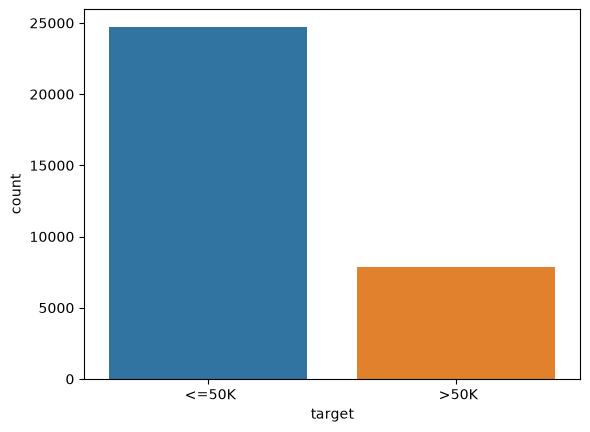

In [6]:
# Analisis de la distribución de la variable target
print( df_50.target.value_counts() )
sns.countplot(x='target', data=df_50, hue='target', legend=False)

In [7]:
# identificamos las variables categóricas
categorical = df_50.select_dtypes(include=['object', 'string']).columns.tolist()
print('las variables categoricas son:\n', categorical)
print("\nchequeamos la dimensionalidad de las variables")
for var in categorical:
    print(len(df_50[var].unique()), ' valores unicos en ', var )

las variables categoricas son:
 ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'target']

chequeamos la dimensionalidad de las variables
9  valores unicos en  workclass
16  valores unicos en  education
7  valores unicos en  marital_status
15  valores unicos en  occupation
6  valores unicos en  relationship
5  valores unicos en  race
2  valores unicos en  sex
42  valores unicos en  native_country
2  valores unicos en  target


In [8]:
# paso target a una variable numerica
df_50['target'] = df_50['target'].apply(lambda x: 1 if x == ' >50K' else 0 )

In [9]:
# identificamos las variables numéricas
numerical = df_50.select_dtypes(include='number').columns.tolist()
print('las variables numéricas son:\n', numerical)

las variables numéricas son:
 ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'target']


# Correlación de Variables

<Axes: >

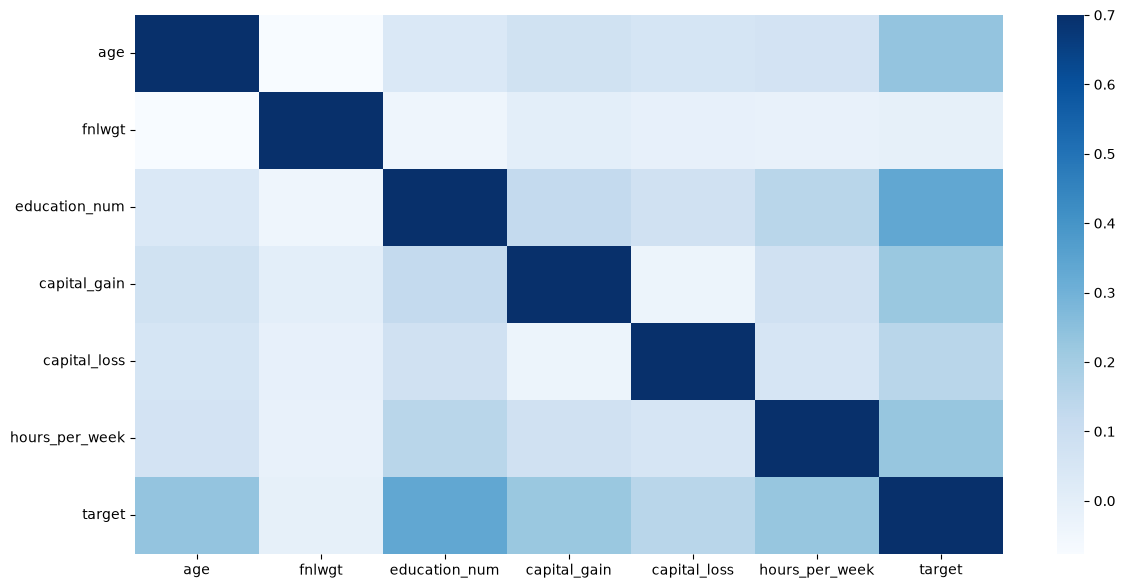

In [10]:
plt.figure(figsize=(14,7))
sns.heatmap(df_50[numerical].corr(), vmax=.7, cmap ='Blues', fmt=".2f")

In [11]:
df_corr = df_50[numerical].corr()[["target"]]*100 # lo pasamos a porcentajes
df_corr = df_corr.drop("target", axis=0) # eliminamos la variable target
df_corr = df_corr.sort_values(["target"], ascending=False) # ordenamos en forma descendente
df_corr = abs(df_corr) # nos interesa el valor absouluto
df_corr

,target
education_num,33.515395
age,23.403710
hours_per_week,22.968907
capital_gain,22.332882
capital_loss,15.052631
fnlwgt,0.946256


# Seleccionamos las variables que vamos a utilizar y hacemos el Split

In [12]:
df_50.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education_num',
       'marital_status', 'occupation', 'relationship', 'race', 'sex',
       'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
       'target'],
      dtype='str')

In [13]:
# usamos todas las columnas numércias
df = df_50[numerical]
X = df.drop("target",axis=1)
y = df["target"]
X.head()

,age,fnlwgt,education_num,capital_gain,capital_loss,hours_per_week
0,39,77516,13,2174,0,40
1,50,83311,13,0,0,13
2,38,215646,9,0,0,40
3,53,234721,7,0,0,40
4,28,338409,13,0,0,40


In [14]:
# Hacemos el Split 70-30 para train-test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify = y, random_state=42)

In [15]:
# Creamos y entrenamos el clasificador bayesiano
bayes_multi = MultinomialNB()
bayes_multi.fit(X_train, y_train) # entrenamos el clasificador

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[17303., 5489.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.28,-1.42]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 6)","[[6.37e+05,3.30e+09,1.66e+05,2.48e+06,9.36e+05,6.73e+05], [2.43e+05,1.03e+09,6.37e+04,2.18e+07,1.03e+06,2.50e+05]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 6)","[[-8.56,-0. ,-9.9 ,-7.2 ,-8.17,-8.5 ], [-8.38,-0.02,-9.71,-3.88,-6.93,-8.35]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['age','fnlwgt','education_num','capital_gain','capital_loss', 'hours_per_week']"


In [16]:
y_pred_nb = bayes_multi.predict(X_test)

#Exactitud del modelo
print('Exactitud (accuracy) del modelo: {:.2f} %'.format(accuracy_score(y_test, y_pred_nb)*100))
print("-"*100)

# Reporte del clasificador
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_nb))

Exactitud (accuracy) del modelo: 77.93 %
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.80      0.95      0.87      7417
           1       0.61      0.24      0.34      2352

    accuracy                           0.78      9769
   macro avg       0.70      0.59      0.60      9769
weighted avg       0.75      0.78      0.74      9769



# Ejercicio
- ¿hay variables redundantes en este dataframe? ¿que variables feature engineering incluirias en este modelo?
- ¿Por qué `GaussianNB` resulta más apropiado que `MultinomialNB` para las variables numéricas de este dataset? ¿Qué tipo de datos modela naturalmente cada variante?
- ¿Por qué no podemos utilizar directamente variables categóricas como `education`, `occupation` o `marital-status` como entrada de `GaussianNB`?
- Usando OneHotEncoder o pd.get_dummies() en las variables categóricas de baja dimensionalidad, obtener columnas numericas para representarlas. incluirlas al modelo y comparar el resultado

1- Solo education es redudante. Binarizaria capital_gain y capital_loss, agruparia native_country (pondira algo como es_usa - si/no), eliminaria education porque es redundante

2- Porque las variables (age, hours_per_week, education_num) son mediciones continuas, no conteos. GaussianNB asume distribución Normal por clase, que es lo que corresponde a datos continuos. MultinomialNB asume conteos de ocurrencias.

3- Porque son texto/nominales, y GaussianNB necesita calcular una media y una varianza numérica por feature.

In [17]:
#4
cat_baja_dim = [c for c in categorical if c not in ['target', 'education', 'occupation', 'native_country']
                and df_50[c].nunique() <= 10]
print('categóricas elegidas para one-hot:', cat_baja_dim)

df_encoded = pd.get_dummies(df_50[cat_baja_dim], drop_first=True)
df_encoded.head()

categóricas elegidas para one-hot: ['workclass', 'marital_status', 'relationship', 'race', 'sex']


,workclass_ Federal-gov,workclass_ Local-gov,workclass_ Never-worked,workclass_ Private,workclass_ Self-emp-inc,workclass_ Self-emp-not-inc,workclass_ State-gov,workclass_ Without-pay,marital_status_ Married-AF-spouse,marital_status_ Married-civ-spouse,...,relationship_ Not-in-family,relationship_ Other-relative,relationship_ Own-child,relationship_ Unmarried,relationship_ Wife,race_ Asian-Pac-Islander,race_ Black,race_ Other,race_ White,sex_ Male
0,False,False,False,False,False,False,True,False,False,False,...,True,False,False,False,False,False,False,False,True,True
1,False,False,False,False,False,True,False,False,False,True,...,False,False,False,False,False,False,False,False,True,True
2,False,False,False,True,False,False,False,False,False,False,...,True,False,False,False,False,False,False,False,True,True
3,False,False,False,True,False,False,False,False,False,True,...,False,False,False,False,False,False,True,False,False,True
4,False,False,False,True,False,False,False,False,False,True,...,False,False,False,False,True,False,True,False,False,False


In [ ]:
X_combinado = pd.concat([df_50[numerical].drop(columns=['fnlwgt', 'target']), df_encoded], axis=1)
y = df_50['target']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_combinado, y, test_size=0.3, stratify=y, random_state=42
)

bayes_gauss = GaussianNB()
bayes_gauss.fit(X_train_c, y_train_c)
y_pred_gauss = bayes_gauss.predict(X_test_c)

print('Exactitud (accuracy) del modelo GaussianNB + one-hot: {:.2f} %'.format(
    accuracy_score(y_test_c, y_pred_gauss) * 100
))
print("-" * 100)
print(classification_report(y_test_c, y_pred_gauss))

Exactitud (accuracy) del modelo GaussianNB + one-hot: 82.01 %
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.89      0.87      0.88      7417
           1       0.62      0.65      0.64      2352

    accuracy                           0.82      9769
   macro avg       0.75      0.76      0.76      9769
weighted avg       0.82      0.82      0.82      9769

